# Direct R+C source fit — start with ID6170

This is a short adaptation of the old `fixed_geometry_mcmc.ipynb` layout for the direct-image method tested in the injection notebook. Use the **grism** kernel and run top to bottom.

One freely fitted, nonnegative emission map is dispersed into both R and C. The fit compares predictions with the original input pixels. Inclination is fitted with a **75° ± 5° Gaussian prior**, and the source center is fixed at **(40.25, 41.0) pixels**. All settings are explicit arguments below.

This experimental stage produces best fits and residuals. It does **not yet provide MCMC uncertainties including the unknown emission map**. There is no explicit PSF or intrinsic velocity-dispersion model. The input images should already have the desired artifact treatment.

In [1]:
from pathlib import Path
import os, sys, importlib, logging
import matplotlib.pyplot as plt
import torch
from IPython.display import display

REPO = Path.cwd() if (Path.cwd() / "dingo").is_dir() else Path("/home/aakavan/kinematics/grism-kinematics")
DATA_DIR = REPO / "data"
CALIBRATION_DIR = REPO.parent / "grism_cal"
OUTPUT_ROOT = REPO.parent / "field_kinematics/edr_kinematics/PaA/dingo_runs"
OVERRIDE = True   # Replace only the named run prepared below
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
torch.set_num_threads(min(4, os.cpu_count() or 1))
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import direct_source, injection_flexible, direct_workflow as direct
for module in (direct_source, injection_flexible, direct):
    importlib.reload(module)
print("Device:", DEVICE)
print("Output root:", OUTPUT_ROOT)

Device: cuda
Output root: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs


## 1. Choose the source and starting values

`prepare` reads `ID6170/image.fits`, `R.fits`, `C.fits`, and its calibration metadata. It does not require a previous fit. Imaging is displayed only; it does not prescribe the gas morphology. The center and offsets are zero-based pixels, and supplied angles are degrees.

The cyan crosses show where the fixed kinematic center projects into the raw R and C images at the starting registration. The R projection can move as registration is fitted.

The existing ID6170 C image contains three large negative pixels near (46,61), (40,55), and (35,49), outside its previously cleaned circle. Inspect their residuals; they are included in this experiment.

ID6170: center fixed at (40.25, 41.0) pixels; fitted i prior 75 +/- 5 degrees.
R/C noise: {'R': 0.0034141347629099, 'C': 0.003515137827137167}
Saving to: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/direct_i75s5_v450_v1


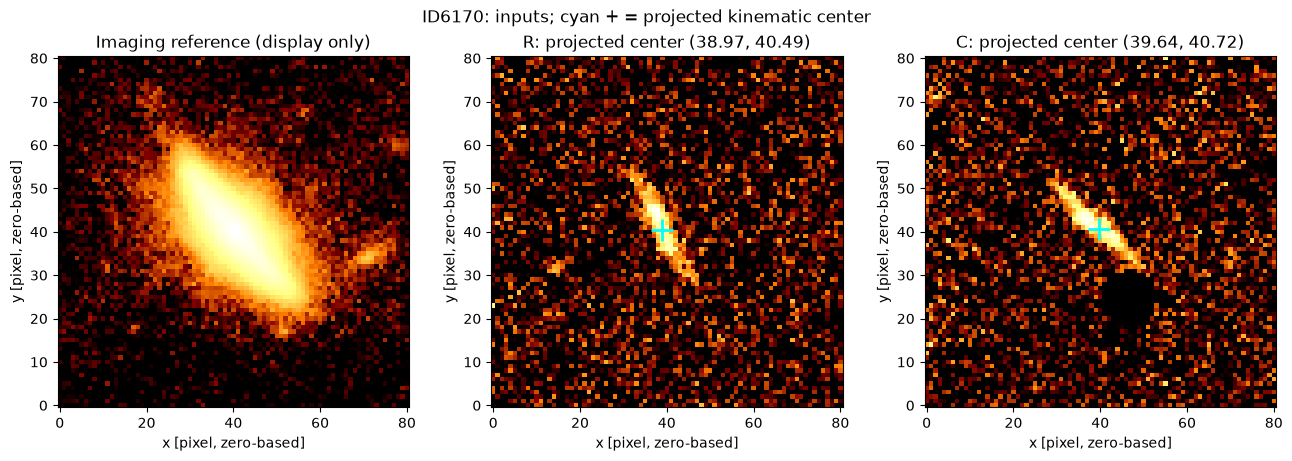

In [2]:
run = direct.prepare(
    6170,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    run_name="direct_i75s5_v450_v1",
    center=(40.25, 41.0),
    inclination_mean=75.0,
    inclination_sigma=5.0,
    start_inclination=75.0,
    start_velocity=450.0,
    start_turnover=10.09,
    start_pa=286.64,
    start_offset=(1.0625, 0.2852),
    max_velocity=1000.0,
    device=DEVICE,
    overwrite=OVERRIDE,
)
fig = direct.show_inputs(run)
display(fig)
plt.close(fig)

## 2. Fit

The fitter varies velocity, turnover radius, orientation, R x/y registration, and inclination. For each trial, it fits a shared emission map from R+C, with no Sérsic shape or smoothing prior. R and C use separate background-noise estimates.

The progress bar counts trial evaluations; `max_evaluations` is a budget, not an MCMC chain length. Best-fit checkpoints and `run_info.txt` are saved as the score improves. Sparse map solves use CPU linear algebra even when the coordinate model uses CUDA.

In [3]:
fit_result = direct.fit(run, max_evaluations=150, progress=True)

Free-map fit evaluations:   0%|          | 0/150 [00:00<?, ?it/s]

Saved best fit: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/direct_i75s5_v450_v1
Optimizer: True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Gradient criterion met: False


## 3. Inspect the results

These panels compare the **original input, direct prediction, and residual divided by noise** for each grism. Residual colors saturate at ±5; the label counts pixels beyond that display range. No finite pixels are omitted from fitting.

The table and figures use the same saved best-fit parameter vector. The curve has no error band because the free-map posterior is not sampled yet. `V_inf` is asymptotic velocity; `V_at_R_t = V_inf / 2` is the velocity at the fitted turnover radius.

To reopen without fitting, call `direct.show_results(OUTPUT_ROOT / "6170" / "direct_i75s5_v450_v1")` in place of the first line below. All outputs are saved inside that run folder.

Status: completed Optimizer: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Gradient criterion met: False Inner optimality: 2.0615037264762e-07
Profile-fit values only; MCMC uncertainties including the emission map are not available.
Results: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/direct_i75s5_v450_v1


,value,unit
V_inf,449.191435,km/s
R_t,11.204025,pixel
cutout_PA,292.703668,deg
R_dx,1.409241,pixel
R_dy,-0.222977,pixel
inclination,74.798997,deg
V_at_R_t,224.595718,km/s


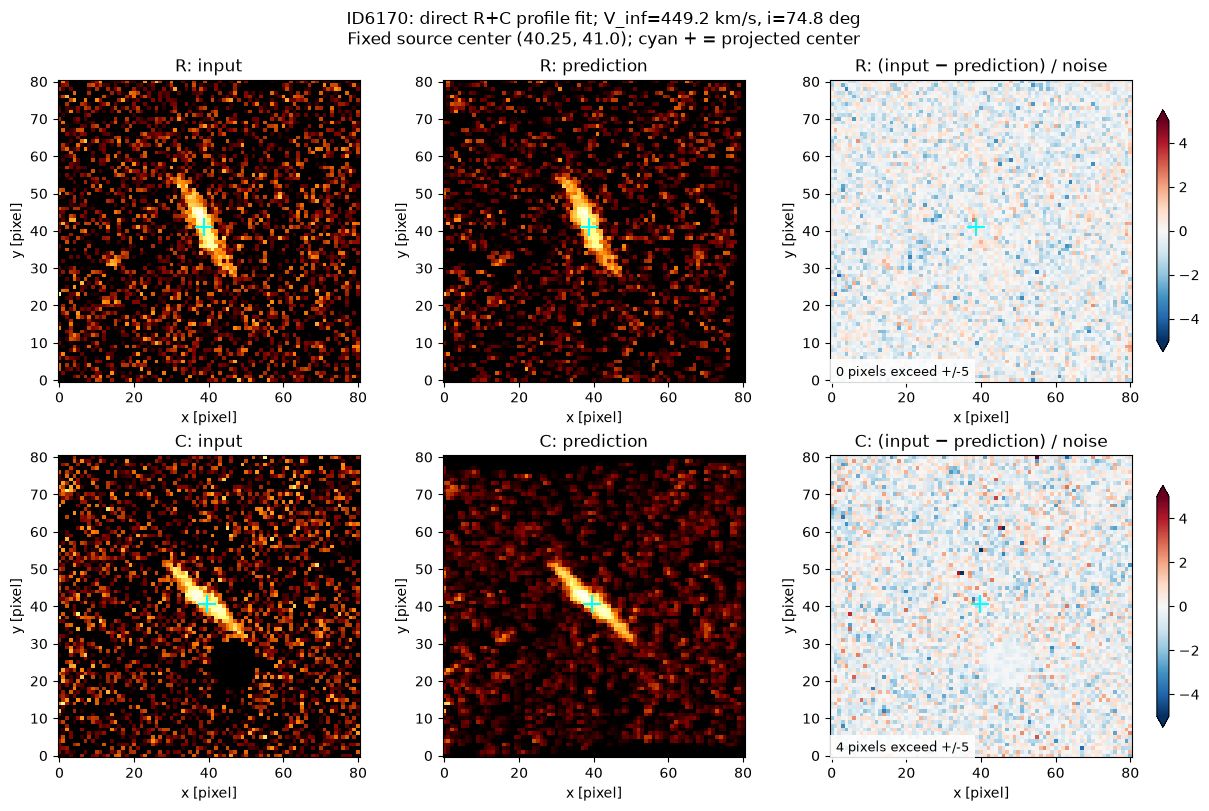

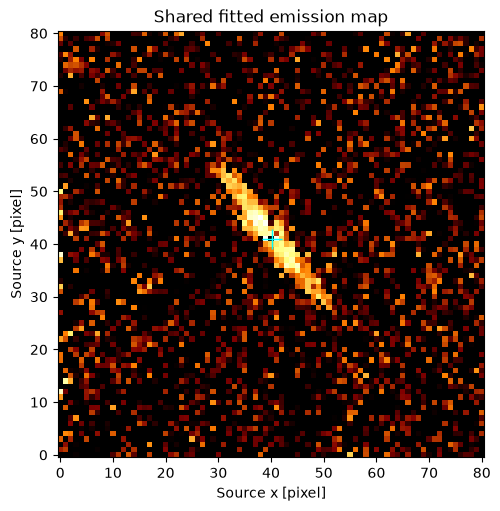

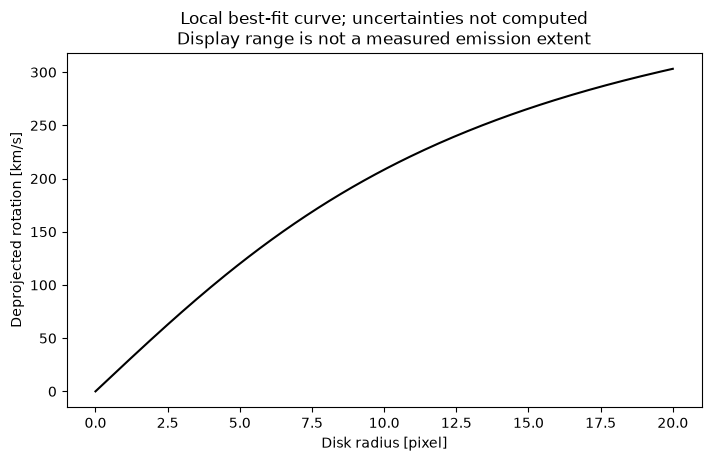

In [4]:
views = direct.show_results(run)
display(views["summary"])
for name in ("residuals", "emission", "rotation_curve"):
    display(views[name])
    plt.close(views[name])

To try another configuration, copy the preparation and fit calls with a new handle such as `run_b` and a different `run_name`. Change the source ID, center, inclination prior, and starting parameters explicitly. Existing runs stay in their own folders.